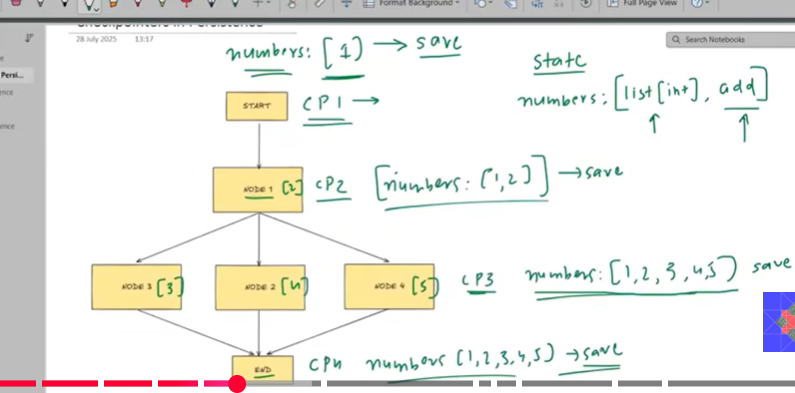

This is the checkpointer concept in persistence , there is a checkpoint at each superstep ,
what is a superstep??? when u go from one node to other node , in between there exists a superstep.
Start -> superstep --> NODE1

between node1 and node2,node3,node4  , there exists one superstep

at each superstep , before and after each superstep , there is a checkpoint.

at each checkpoint intermediate states are stored

Each conversation , each time you INVOKE , you invoke with a thread_id , such that now each convo has a unique thread_id ,
so when u want to resume a convo a day later , u can just get the thread_id and get your old conversation back and resume the particular convo

In [37]:
from langgraph.graph import StateGraph , START , END 
from typing import TypedDict , Annotated
from langchain_core.messages import BaseMessage , HumanMessage , AIMessage 
from langgraph.checkpoint.memory import MemorySaver


In [38]:
class JokeState(TypedDict):
    joke : str
    explanation : str
    topic : str

In [39]:
from groq import Groq

def generate_joke(state : JokeState)->JokeState:
    prompt = f'Write a joke on the topic {state['topic']}'

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
      {
        "role": "user",
        "content": prompt
      }
    ],
    temperature=1,
    max_completion_tokens=8192,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
    stop=None
    )
    
    answer = ''
    for chunk in completion:
        answer += chunk.choices[0].delta.content or ""

    return {'joke' : answer}


def generate_explanation(state : JokeState) -> JokeState:
    prompt = f'write an explanation for the joke - {state["joke"]}'

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[
      {
        "role": "user",
        "content": prompt
      }
    ],
    temperature=1,
    max_completion_tokens=8192,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
    stop=None
    )

    answer = ""
    for chunk in completion:
        answer += chunk.choices[0].delta.content or ""

    return {'explanation' : answer}

In [40]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke' , generate_joke)
graph.add_node('generate_explanation' , generate_explanation)

graph.add_edge(START , 'generate_joke')
graph.add_edge('generate_joke' , 'generate_explanation')
graph.add_edge('generate_explanation' , END)

In [41]:
from langgraph.checkpoint.memory import InMemorySaver
checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer = checkpointer)

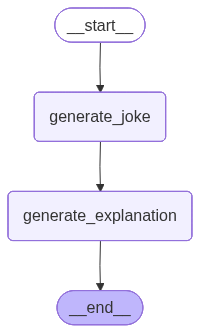

In [42]:
workflow

In [43]:
config = {'configurable' : {'thread_id' : "1"}}
workflow.invoke({'topic' : 'AI'} , config = config)

{'joke': 'Why did the AI start a gardening business?  \n\nBecause it heard it could finally put its “roots” into a *real* *grow*‑th!',
 'explanation': '**Why the joke works – a quick “root‑level” explanation**\n\n| Element | What’s being played on | Why it’s funny |\n|---------|-----------------------|----------------|\n| **“roots”** | 1. The literal roots of a plant<br>2. The figurative “root” of a computer algorithm (the base, starting point) | It lets us think of the AI as a plant‑like entity that can now *literally* get its roots in the ground, while also nodding to the technical “root” of a data structure. The double‑meaning creates a surprise twist. |\n| **“real grow‑th”** | 1. “Real growth” – the idea of something actually increasing<br>2. “grow‑th” – a playful split of the word *growth* that sounds like “grow‑th” (grow‑th = “grow‑th” = *grow* + “th”) | The joke hinges on the sound of “growth” being broken into “grow‑th.” It’s a pun on “grow” (what a gardener does) and “th,” the

In [ ]:
workflow.get_state(config)
# shows the final state value

StateSnapshot(values={'joke': 'Why did the AI start a gardening business?  \n\nBecause it heard it could finally put its “roots” into a *real* *grow*‑th!', 'explanation': '**Why the joke works – a quick “root‑level” explanation**\n\n| Element | What’s being played on | Why it’s funny |\n|---------|-----------------------|----------------|\n| **“roots”** | 1. The literal roots of a plant<br>2. The figurative “root” of a computer algorithm (the base, starting point) | It lets us think of the AI as a plant‑like entity that can now *literally* get its roots in the ground, while also nodding to the technical “root” of a data structure. The double‑meaning creates a surprise twist. |\n| **“real grow‑th”** | 1. “Real growth” – the idea of something actually increasing<br>2. “grow‑th” – a playful split of the word *growth* that sounds like “grow‑th” (grow‑th = “grow‑th” = *grow* + “th”) | The joke hinges on the sound of “growth” being broken into “grow‑th.” It’s a pun on “grow” (what a gardener

In [ ]:
list(workflow.get_state_history(config))
# intermediate states , each state is given before running each node
# bottom most is before running START
# and so on 

[StateSnapshot(values={'joke': 'Why did the AI start a gardening business?  \n\nBecause it heard it could finally put its “roots” into a *real* *grow*‑th!', 'explanation': '**Why the joke works – a quick “root‑level” explanation**\n\n| Element | What’s being played on | Why it’s funny |\n|---------|-----------------------|----------------|\n| **“roots”** | 1. The literal roots of a plant<br>2. The figurative “root” of a computer algorithm (the base, starting point) | It lets us think of the AI as a plant‑like entity that can now *literally* get its roots in the ground, while also nodding to the technical “root” of a data structure. The double‑meaning creates a surprise twist. |\n| **“real grow‑th”** | 1. “Real growth” – the idea of something actually increasing<br>2. “grow‑th” – a playful split of the word *growth* that sounds like “grow‑th” (grow‑th = “grow‑th” = *grow* + “th”) | The joke hinges on the sound of “growth” being broken into “grow‑th.” It’s a pun on “grow” (what a gardene